In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Series的创建

## 直接创建Series

In [4]:
s = pd.Series([4, 7, -5, 3])
print(s, type(s))

0    4
1    7
2   -5
3    3
dtype: int64 <class 'pandas.Series'>


## 在创建的时候指定索引和名称

In [6]:
s = pd.Series(data=[10, 20, 30, 40, 50], index=['a', 'b', 'c', 'd', 'e'], name="hello")
print(s, type(s))

a    10
b    20
c    30
d    40
e    50
Name: hello, dtype: int64 <class 'pandas.Series'>


## 通过字典创建Series

In [7]:
s = pd.Series({'a': 10, 'b': 20, 'c': 30, 'd': 40, 'e': 50})
s

a    10
b    20
c    30
d    40
e    50
dtype: int64

## Series的常用属性

In [21]:
arrs = pd.Series([11, 22, 33, 44, 55], name='atguigu', index=['a', 'b', 'c', 'd', 'e'])
arrs.shape
arrs.index
arrs.values
arrs.loc['a': 'd']
arrs.iloc[0: 4]

a    11
b    22
c    33
d    44
Name: atguigu, dtype: int64

## Series的常用方法

<Axes: >

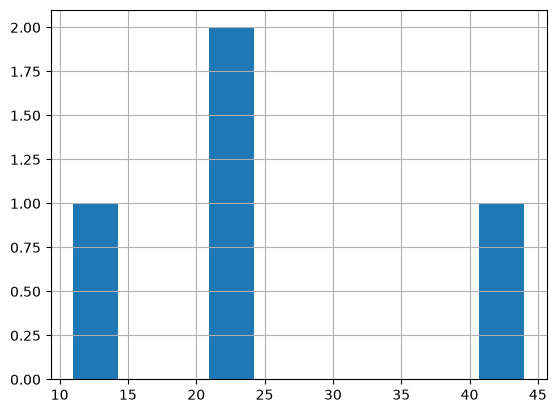

In [72]:
arr = pd.Series([11, 22, np.nan, None, 44, 22], ['a', 'b', 'c', 'd', 'e', 'f'])
arr2 = arr.head(3)
arr.tail(3)
arr.isin([11, 22, 33])
arr.isna()
arr.sum()
arr.min()
arr.max()
arr.var() # 会直接省略缺省值
arr.std()
arr.median()
arr2 = arr.mode()
arr.quantile(0.25)
arr.describe()
arr.value_counts().shape
arr.count()
len(arr)
type(arr.drop_duplicates())
type(arr.unique())
arr.sample()
arr.sort_values().reset_index(drop=True) # 按值排序之后，重新设置索引
type(arr.to_frame())
arr.replace(22, np.nan)
arr.keys()
arr.hist()

## Series布尔索引

In [ ]:
s = pd.Series({'a': -1.2, 'b': 3.5, 'c': 6.8, 'd': 2.9})
s[s > 3]

b    3.5
c    6.8
dtype: float64

## Series的运算

### Series与标量进行运算 --- Series中的每个元素都会和标量进行运算 

In [80]:
s = pd.Series({'a': -1.2, 'b': 3.5, 'c': 6.8, 'd': 2.9})
s * 10

a   -12.0
b    35.0
c    68.0
d    29.0
dtype: float64

### Series与Series进行运算  会根据标签索引进行对位计算，索引没有匹配上的会用NaN填充

In [85]:
s1 = pd.Series([1, 1, 1, 1], index=[1, 2, 3, 4])
s2 = pd.Series([2, 2, 3, 2], index=[0, 1, 2, 3])
s1 * s2

0    NaN
1    2.0
2    3.0
3    2.0
4    NaN
dtype: float64

## DataFrame 的创建

### 直接通过字典创建 DataFrame

In [86]:
df = pd.DataFrame({"id": [101, 102, 103], "name": ["张三", "李四", "王五"], "age": [20, 30, 40]})
df

,id,name,age
0,101,张三,20
1,102,李四,30
2,103,王五,40


### 由多个索引相同的Series组成

In [87]:
mango_Series = pd.Series([4, 5, 6, 3, 1])
apple_Series = pd.Series([5, 4, 3, 0, 2])
banana_Series = pd.Series([2, 3, 5, 2, 7])

df = pd.DataFrame({"mango": mango_Series, "apple": apple_Series, "banana": banana_Series})
df

,mango,apple,banana
0,4,5,2
1,5,4,3
2,6,3,5
3,3,0,2
4,1,2,7


### DataFrame 的常用属性

In [31]:
import pandas as pd
df = pd.DataFrame({"id": [101, 102, 103], "name": ["张三", "李四", "王五"], "age": [20, 30, 40]}, index=["aa", "bb", "cc"])
df.index
type(df.columns)
df.ndim
df.shape
df.size
df.dtypes
type(df.name)
type(df.values)
df1 = df.T
df1.index
type(df[["name", "age"]])

pandas.DataFrame

### DataFrame常用的方法

In [51]:
df = pd.DataFrame(data={"id": [101, 105, 103, 104, 102, 106, 101], "name": ["张三", "李四", "王五", "赵六", "吕七", "周八"
    , "张三"], "age": [10, 20, 30, 40, None, 60, 10]}, index=["aa", "bb", "cc", "dd", "ee", "ff", "aa"])
df.head()
df.tail()
df.isin(["张三", 30])
df.isna()
df.min().age
df.max().id
df.age.var()
df.describe(include="string")
df.id.diff()
df.sort_values("id")

,id,name,age
aa,101,张三,10.0
aa,101,张三,10.0
ee,102,吕七,NaN
cc,103,王五,30.0
dd,104,赵六,40.0
bb,105,李四,20.0
ff,106,周八,60.0


### DataFrame的布尔索引

In [54]:
df = pd.DataFrame({"age": [20, 30, 40, 10], "name": ["张三", "李四", "王五", "赵六"]}, columns=["name", "age"], index=[101, 104, 103, 102])
df["age"] > 30
df[df["age"] > 20]

,name,age
104,李四,30
103,王五,40


### DataFrame的更改操作

In [13]:
import pandas as pd
df = pd.DataFrame({"age": [20, 30, 40, 10], "name": ["张三", "李四", "王五", "赵六"], "id": [101, 102,103, 104]})
df

,age,name,id
0,20,张三,101
1,30,李四,102
2,40,王五,103
3,10,赵六,104


### `set_index()`设置行标签

In [14]:
df.set_index("id", inplace=True)
df.reset_index(inplace=True)

### `rename()`修改行标签和列标签

In [17]:
df.rename(index={0: "一", 1: "二"}, columns={"age": "年龄", "name": "名字"})

,id,年龄,名字
一,101,20,张三
二,102,30,李四
2,103,40,王五
3,104,10,赵六


### DataFrame数据的导入和导出


In [19]:
import os
import pandas as pd

os.makedirs("data", exist_ok=True)
df = pd.DataFrame({"age": [20, 30, 40, 10], "name": ["张三", "李四", "王五", "赵六"], "id": [101, 102, 103, 104]})
df.set_index("id", inplace=True)
df

,age,name
id,,
101,20,张三
102,30,李四
103,40,王五
104,10,赵六


In [20]:
df.to_csv("data/data.csv")

### 数据的导入

In [22]:
df = pd.read_csv("data/data.csv", encoding="utf-8")
df

,id,age,name
0,101,20,张三
1,102,30,李四
2,103,40,王五
3,104,10,赵六


### 日期类型元素

In [31]:
import pandas as pd
df = pd.DataFrame({"gmv": [100, 200, 300, 400], "trade_date": ["2025-01-06", "2023-10-31", "2023-12-31", "2023-01-05"]})
df['ymd'] = pd.to_datetime(df["trade_date"])
df["ymd"].dt.year[2]

np.int32(2023)

### 天气案例基本切片

In [19]:
import pandas as pd
df = pd.read_csv("../data/weather.csv")
df.head()
df.dtypes

date                 str
precipitation    float64
temp_max         float64
temp_min         float64
wind             float64
weather              str
dtype: object

### 属性相关操作

<Axes: xlabel='month'>

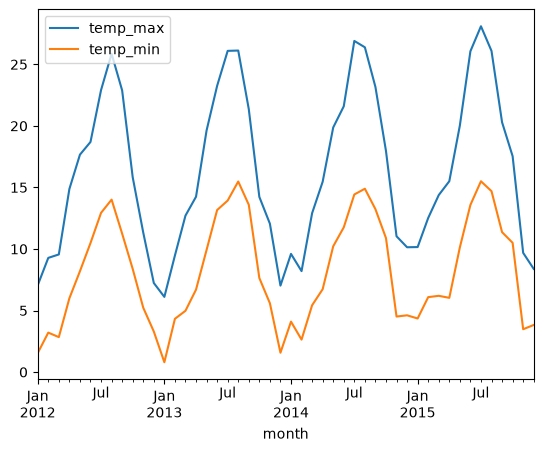

In [34]:
import matplotlib.pyplot as plt
# 分组聚合
df["month"] = (pd.to_datetime(df["date"])).dt.to_period('M')

# 按照月份来进行分组
df_groupby = df.groupby("month")

# 过滤要聚合的字段
df_columns = df_groupby[["temp_max", "temp_min"]]

# 聚合
df_columns.mean().plot()

In [33]:
# 统计每个月不同天气的数量
df.groupby("month")["weather"].nunique().head()

month
2012-01    4
2012-02    4
2012-03    4
2012-04    4
2012-05    3
Freq: M, Name: weather, dtype: int64

### 常用的降序方法

In [39]:
# 找到最高温度最大的30天
df.nlargest(30, ["temp_max"]).head(30)

# 找出每年的最高温度
df["year"] = pd.to_datetime(df["date"]).dt.to_period("Y")
df.groupby("year")["temp_max"].max().head()

year
2012    34.4
2013    33.9
2014    35.6
2015    35.0
Freq: Y-DEC, Name: temp_max, dtype: float64